In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

In [35]:

data = pd.read_csv("../dataset/creditcard.csv")

print(data.shape)
print(data.columns.tolist())

(284807, 31)
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [36]:
import os

print(os.getcwd())
print(os.path.exists("../dataset/creditcard.csv"))

/Users/srishtikumari/Desktop/Credit-Card-Fraud-Detection/notebooks
True


In [37]:
data = pd.read_csv("../dataset/creditcard.csv")

print(data.shape)
print(data.head())


(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

In [38]:
# 3. Initial Exploration
print(data.head())
print(data.info())
print(data.describe())


   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 


Class Distribution:
 Class
0    284315
1       492
Name: count, dtype: int64


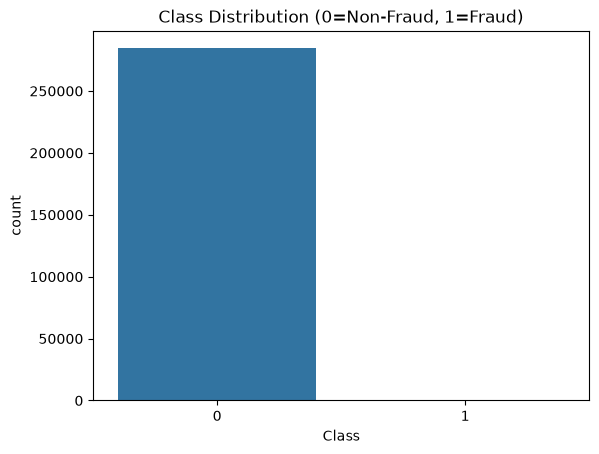

In [39]:
# 4. Check Class Distribution
fraud_count = data['Class'].value_counts()
print("\nClass Distribution:\n", fraud_count)
sns.countplot(x='Class', data=data)
plt.title('Class Distribution (0=Non-Fraud, 1=Fraud)')
plt.show()

In [40]:
# 5. Missing Values
print("\nMissing Values:\n", data.isnull().sum())



Missing Values:
 Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [41]:
data = pd.read_csv("../dataset/creditcard.csv")

In [42]:
print(data.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data['normAmount'] = scaler.fit_transform(data[['Amount']])
data['normTime'] = scaler.fit_transform(data[['Time']])

data.drop(['Time', 'Amount'], axis=1, inplace=True)

In [44]:
import pandas as pd

data = pd.read_csv("../dataset/creditcard.csv")

print(data.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [45]:
data.drop(['Time', 'Amount'], axis=1, inplace=True, errors='ignore')

In [46]:
import pandas as pd

data = pd.read_csv("../dataset/creditcard.csv")

print(data.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [47]:
# 6. Data Preprocessing

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data['normAmount'] = scaler.fit_transform(data[['Amount']])
data['normTime'] = scaler.fit_transform(data[['Time']])

data.drop(columns=['Time', 'Amount'], inplace=True)

print(data.head())

         V1        V2        V3        V4        V5        V6        V7  \
0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9       V10  ...       V22       V23       V24       V25  \
0  0.098698  0.363787  0.090794  ...  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425 -0.166974  ... -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  0.207643  ...  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024 -0.054952  ...  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  0.753074  ...  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28  Class  normAmount  normTime  
0 -0.

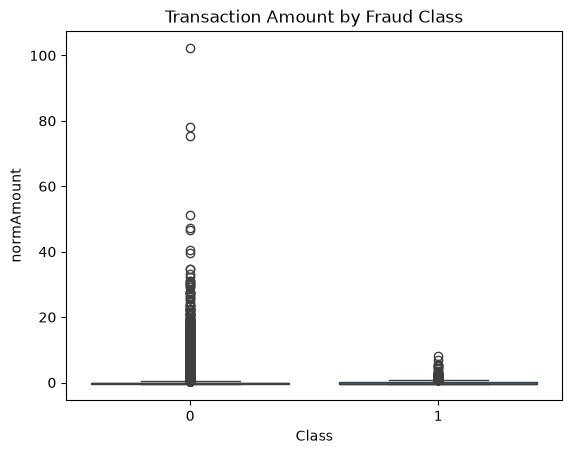

In [48]:
# 7. Transaction Amount Analysis by Class
sns.boxplot(x='Class', y='normAmount', data=data)
plt.title("Transaction Amount by Fraud Class")
plt.show()

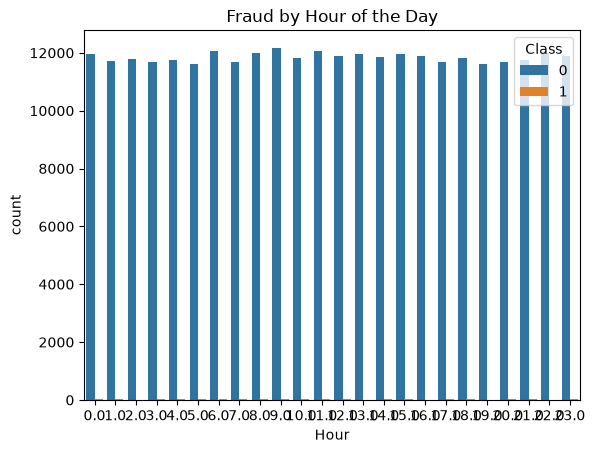

In [49]:

# 8. Time-Based Fraud Pattern (Hour of the day)
data['Hour'] = (data['normTime'] * data.shape[0] * 30) // 3600 % 24
sns.countplot(x='Hour', hue='Class', data=data)
plt.title("Fraud by Hour of the Day")
plt.show()


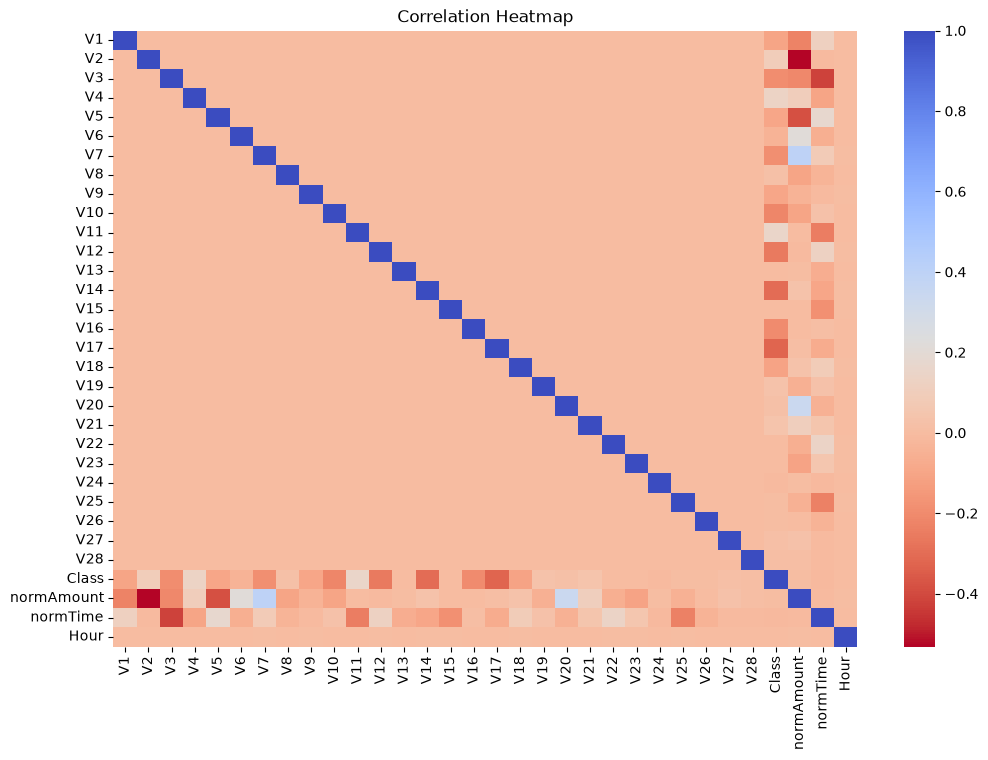

In [50]:
# 9. Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), cmap="coolwarm_r", annot=False)
plt.title("Correlation Heatmap")
plt.show()


In [51]:
# 10. Train-Test Split
X = data.drop('Class', axis=1)
y = data['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


In [52]:
# 11. Model 1: Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_proba_lr = lr.predict_proba(X_test)[:, 1]


In [53]:
print("\n--- Logistic Regression ---")
print(classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba_lr))



--- Logistic Regression ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56851    13]
 [   36    62]]
ROC AUC Score: 0.9579230573771434


In [54]:
# --- Custom Descriptive Results for Logistic Regression ---
report = classification_report(y_test, y_pred_lr, output_dict=True)
precision_1 = report['1']['precision']
recall_1 = report['1']['recall']
f1_1 = report['1']['f1-score']
support_1 = report['1']['support']
support_0 = report['0']['support']
accuracy = (y_pred_lr == y_test).mean()
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr).ravel()
roc_auc = roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1])

print(f"\nDescriptive Logistic Regression Evaluation:\n")
print(f"Precision for class 1 (fraud) ~{precision_1:.2f} means out of all predicted frauds, {precision_1*100:.0f}% were actually fraud.\n")
print(f"Recall for class 1 ~{recall_1:.2f} means it correctly detects {recall_1*100:.0f}% of actual frauds — not perfect but decent given the imbalance.\n")
print(f"F1-score ~{f1_1:.2f} balances precision and recall.\n")
print(f"Support: {support_1:.0f} fraud cases in test, {support_0:.0f} non-fraud.\n")
print(f"Accuracy ~{accuracy:.2f} — high, but expected due to class imbalance (most transactions are non-fraud).\n")
print(f"Confusion Matrix shows most non-fraud correctly identified ({tn}), {fp} false positives, {fn} false negatives, {tp} true positives.\n")
print(f"ROC AUC ~{roc_auc:.3f} — strong overall classification power.\n")



Descriptive Logistic Regression Evaluation:

Precision for class 1 (fraud) ~0.83 means out of all predicted frauds, 83% were actually fraud.

Recall for class 1 ~0.63 means it correctly detects 63% of actual frauds — not perfect but decent given the imbalance.

F1-score ~0.72 balances precision and recall.

Support: 98 fraud cases in test, 56864 non-fraud.

Accuracy ~1.00 — high, but expected due to class imbalance (most transactions are non-fraud).

Confusion Matrix shows most non-fraud correctly identified (56851), 13 false positives, 36 false negatives, 62 true positives.

ROC AUC ~0.958 — strong overall classification power.



In [55]:
# 12. Model 2: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

rf = RandomForestClassifier(
    n_estimators=30,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("--- Random Forest ---")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba_rf))

--- Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.80      0.86        98

    accuracy                           1.00     56962
   macro avg       0.97      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56859     5]
 [   20    78]]
ROC AUC Score: 0.9534704357263445


In [56]:
print(X_train.shape)
print(y_train.shape)
print("Training data ready")

(227845, 31)
(227845,)
Training data ready


In [57]:
print("Testing Jupyter")

Testing Jupyter


In [58]:
print("Hello")

Hello


In [59]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=10,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Training started")

rf.fit(X_train, y_train)

print("Training completed")

Training started
Training completed


In [60]:
print(y_test.shape)
print(y_proba_lr.shape)
print(y_proba_rf.shape)

(56962,)
(56962,)
(56962,)


In [61]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

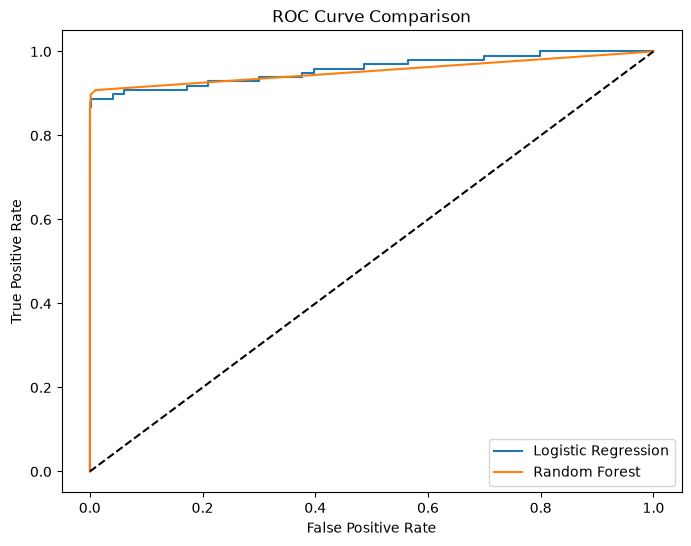

In [62]:
# 13. ROC Curve Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label="Logistic Regression")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

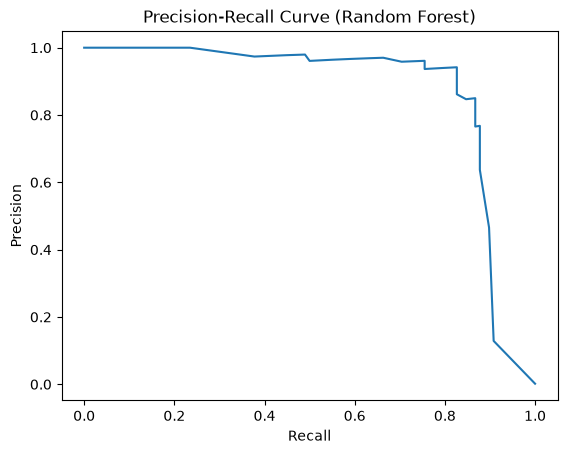

In [63]:
# 14. Precision-Recall Curve (Random Forest)
precision, recall, _ = precision_recall_curve(y_test, y_proba_rf)
plt.plot(recall, precision)
plt.title("Precision-Recall Curve (Random Forest)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

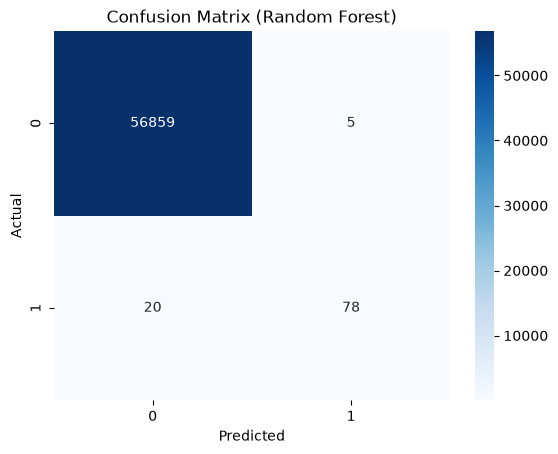

In [64]:
# 15. Confusion Matrix as Heatmap (Random Forest)
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix (Random Forest)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

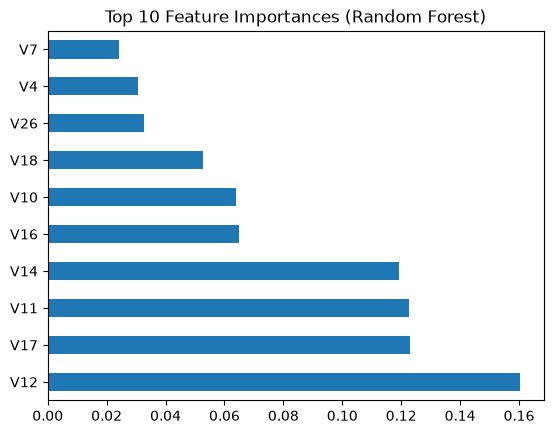

In [65]:
# 16. Feature Importance (Random Forest)
feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh')
plt.title("Top 10 Feature Importances (Random Forest)")
plt.show()


In [66]:
# 17. Summary
print("\nSUMMARY:")
print("• Dataset is highly imbalanced (fraudulent transactions ≈ 0.17%)")
print("• Both Logistic Regression and Random Forest performed well with ROC AUC > 0.90")
print("• Random Forest showed better recall — critical for fraud detection")
print("• Precision-Recall curve and confusion matrix give better insights for imbalanced data")
print("• Top features (V-values) identified by Random Forest can inform further feature engineering")


SUMMARY:
• Dataset is highly imbalanced (fraudulent transactions ≈ 0.17%)
• Both Logistic Regression and Random Forest performed well with ROC AUC > 0.90
• Random Forest showed better recall — critical for fraud detection
• Precision-Recall curve and confusion matrix give better insights for imbalanced data
• Top features (V-values) identified by Random Forest can inform further feature engineering


In [67]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 237.5 kB/s  0:00:09 eta 0:00:02


In [68]:
# 13. Model 3: XGBoost Classifier

from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

print("\n--- XGBoost ---")
print(classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("ROC AUC Score:", roc_auc_score(y_test, y_proba_xgb))


--- XGBoost ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.90      0.78      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
 [[56856     8]
 [   22    76]]
ROC AUC Score: 0.9627460579054357


In [69]:
# 14. Model Comparison

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": (y_pred_lr, y_proba_lr),
    "Random Forest": (y_pred_rf, y_proba_rf),
    "XGBoost": (y_pred_xgb, y_proba_xgb)
}

for name, (pred, proba) in models.items():
    print("\n", name)
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))
    print("ROC AUC:", roc_auc_score(y_test, proba))


 Logistic Regression
Precision: 0.8266666666666667
Recall: 0.6326530612244898
F1 Score: 0.7167630057803468
ROC AUC: 0.9579230573771434

 Random Forest
Precision: 0.9397590361445783
Recall: 0.7959183673469388
F1 Score: 0.861878453038674
ROC AUC: 0.9534704357263445

 XGBoost
Precision: 0.9047619047619048
Recall: 0.7755102040816326
F1 Score: 0.8351648351648352
ROC AUC: 0.9627460579054357


In [70]:
!pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 958.9 kB/s  0:00:00m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]1/2 [shap]


In [72]:
# 15. SHAP Explainability

import shap

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


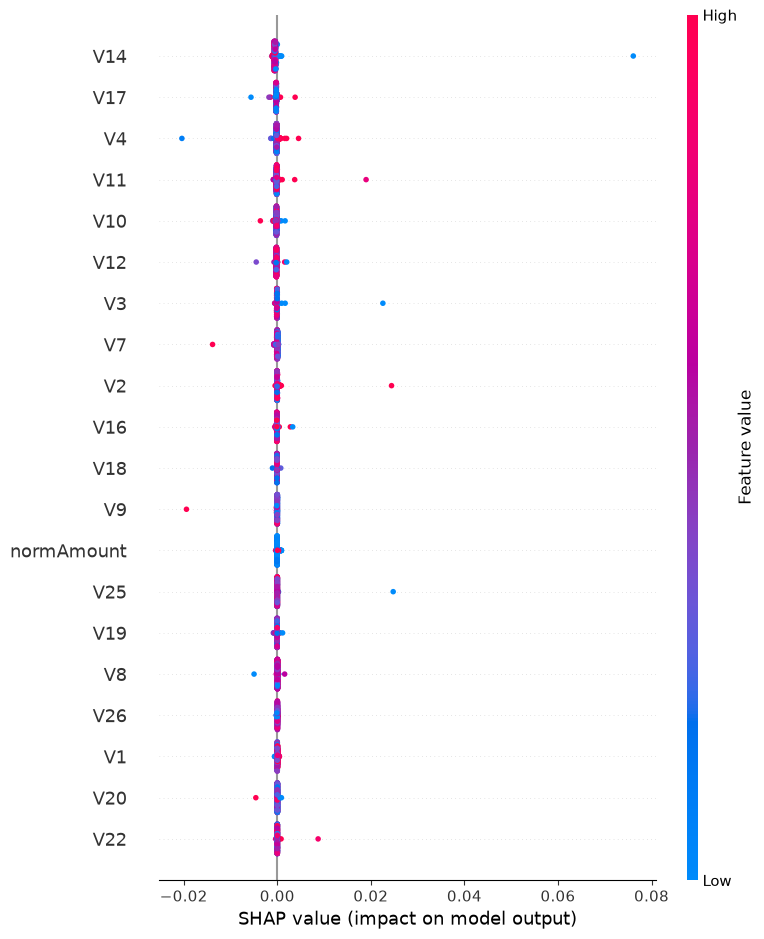

In [75]:
# 16. SHAP Summary Plot

import shap
import matplotlib.pyplot as plt

X_sample = X_test.sample(500, random_state=42)

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_sample)

shap_values_positive = shap_values[1] if isinstance(shap_values, list) else shap_values

if hasattr(shap_values_positive, "values"):
    shap_values_positive = shap_values_positive.values

if len(shap_values_positive.shape) == 3:
    shap_values_positive = shap_values_positive[:, :, 1]

shap.summary_plot(shap_values_positive, X_sample)

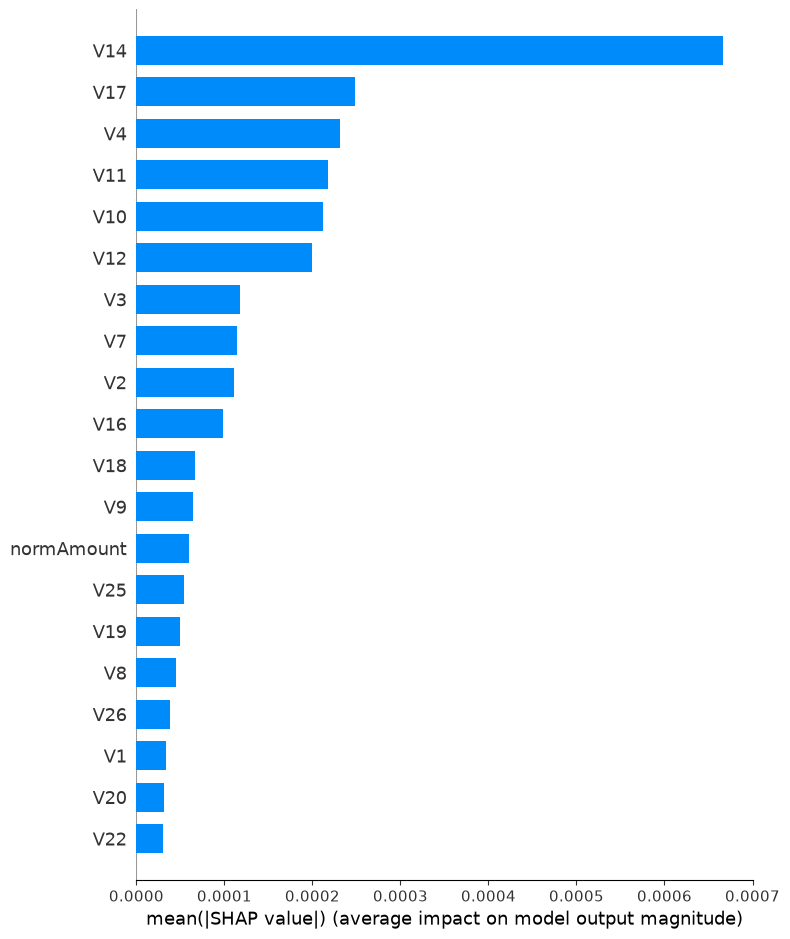

In [76]:
# 17. SHAP Feature Importance

shap.summary_plot(
    shap_values_positive,
    X_sample,
    plot_type="bar"
)

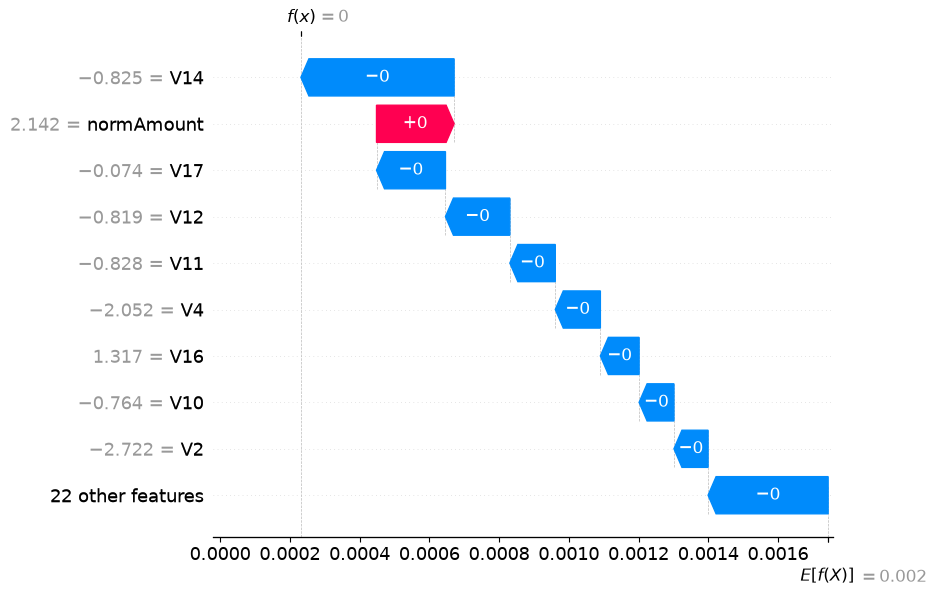

In [79]:
# 18. Individual Transaction Explanation

shap_values_single = explainer(X_sample.iloc[[0]])

shap.plots.waterfall(shap_values_single[0, :, 1])

In [80]:
# 19. Save Trained Models

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(lr, "models/logistic_regression.pkl")
joblib.dump(rf, "models/random_forest.pkl")
joblib.dump(xgb, "models/xgboost.pkl")

print("All models saved successfully!")

All models saved successfully!


In [81]:
!pip install streamlit

In [82]:
# Check saved model features
print("Features:")
print(list(rf.feature_names_in_))

# Check fitted scalers
print("\nAvailable scalers:")
print([
    name for name, obj in globals().items()
    if "Scaler" in type(obj).__name__
])

Features:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'normAmount', 'normTime', 'Hour']

Available scalers:
['scaler']
